# 14 · Explaining the final model: token probabilities and SHAP values

The final model (notebook 13) has two levels, and each is explained with the tool that fits it:

1. **Token level: where in a text does the model see AI writing?** The two token taggers (notebooks 10 and 12) give
   every token a probability of being AI-written; their average is the input of the stacker's tagger features. These
   probabilities are a direct *token attribution*: they can be laid over the text and compared with the AI sections
   recovered in notebook 08. Example texts (found, missed, false alarm), the average probability around the start and
   end of AI sections, and the words that cause false alarms in human texts.
2. **Text level: which features decide human / fusion / ai?** The stacker is gradient boosting on 80 features.
   **SHAP values** (Lundberg & Lee, 2017) split each prediction into additive contributions of the features: the
   contribution of a feature is its average effect on the class score over all orders in which features can be
   added (the Shapley value from game theory). For tree models they are computed exactly (TreeSHAP). They are in the
   units of the model's class scores (log-odds before the softmax): positive pushes towards the class.

The explained stacker is the best single boosting model of notebook 13 (300 trees, learning rate 0.05, 31 leaves),
which scores the same as the bagged final model (0.9718). Every validation text is explained by the fold model that
did not see it in training, as in the out-of-fold scores.

In [1]:
# Setup: clone/update the repo on Colab/Kaggle, install requirements, resolve paths, get the data
import os, sys, subprocess
REPO_URL = "https://github.com/anna-kryvulia/ucu-ai-hw-generated-text-detection.git"
BRANCH = "main"   # branch with the code you pushed
if "google.colab" in sys.modules or os.path.exists("/kaggle/working"):
    ROOT = "/content/repo" if "google.colab" in sys.modules else "/kaggle/working/repo"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{ROOT}/requirements.txt"], check=True)
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, f"{ROOT}/src")

from hwkit import env
from hwkit.download import ensure_data
from hwkit.tracker import Run
P = env.setup(seed=42)
ensure_data(P)

platform: local
    data: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/data
 outputs: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/outputs
   cache: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/outputs/cache
    repo: /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection
  device: mps
data ready at /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/data


PosixPath('/Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/data')

In [2]:
# Imports, config; validation texts with their recovered AI sections (notebook 08)
import html
import re
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import HTML, display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder

from hwkit.config import load_config
from hwkit.final import FINAL_BLOCKS, averaged_tokens, feature_blocks
from hwkit.split import LABELS, load_split, scores
from hwkit.stack import group_folds
from hwkit.tagger import token_labels

NOTEBOOK_START = time.time()
cfg = load_config("xai")
XC = cfg["explain"]
FIG = P.outputs / "figures"
FIG.mkdir(parents=True, exist_ok=True)

val = load_split(pd.read_csv(P.data / "train.csv", usecols=["id", "text", "label", "domain", "lang"]))
val = val[val["fold"] == 0].reset_index(drop=True)
val["domain_lang"] = val["domain"] + " | " + val["lang"]
spans = pd.read_csv(P.repo / "results" / "fusion_spans.csv.gz").set_index("id")
val = val.join(spans[["ai_share", "n_spans", "spans"]], on="id")
val["words"] = val["text"].str.split().str.len()
y = val["label"].map({c: i for i, c in enumerate(LABELS)}).to_numpy()
w = val["weight"].to_numpy()
folds = group_folds(val, cfg["cv"]["folds"])
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(val[["domain_lang"]])
run = Run(cfg["name"], cfg, P)
print(f"validation: {len(val)} texts; fusion texts with recovered AI sections: {val['spans'].notna().sum()}")

run 'xai' at /Users/anna/Desktop/AI/ucu-ai-hw-generated-text-detection/outputs/runs/xai  done: nothing yet
validation: 27236 texts; fusion texts with recovered AI sections: 7636


In [3]:
# Feature blocks of notebook 13; one boosting model per fold (the explained model); its out-of-fold score
t0 = time.time()
blocks = feature_blocks(P.runs, cfg, "val", val, ohe)
X = pd.concat([blocks[b] for b in FINAL_BLOCKS], axis=1)
Xv, NAMES = X.to_numpy(), X.columns
GROUP_NAMES = {"shape": "encoders: chunk shape", "text": "text statistics", "tagger": "tagger 1: summaries (nb 10)",
               "fine1": "tagger 1: finer summaries", "avg": "both taggers averaged"}
def group_of(block, col):
    if block != "base":
        return GROUP_NAMES[block]
    if col.startswith("tfidf_"):
        return "TF-IDF baseline"
    return "domain and language" if col in ohe.categories_[0] else "encoders: text probabilities"
GROUP = pd.Series({c: group_of(b, c) for b in FINAL_BLOCKS for c in blocks[b].columns})[NAMES]

params = {**cfg["boosting"], **XC["boosting"]}
models = [HistGradientBoostingClassifier(**params, early_stopping=False, random_state=42)
          .fit(Xv[folds != k], y[folds != k], sample_weight=w[folds != k]) for k in range(cfg["cv"]["folds"])]
oof = np.zeros((len(val), len(LABELS)))
for k, m in enumerate(models):
    oof[folds == k] = m.predict_proba(Xv[folds == k])
pred = np.array(LABELS)[oof.argmax(axis=1)]
res = scores(val["label"], pred, val["weight"])
run.log_metrics("explained model (out-of-fold)", res)
print(f"{Xv.shape[1]} features; out-of-fold test-like macro-F1 {res['macro_f1_testlike']:.4f} "
      f"(notebook 13: 0.9718); {(time.time() - t0) / 60:.1f} min")

80 features; out-of-fold test-like macro-F1 0.9718 (notebook 13: 0.9718); 3.6 min


The fold models reproduce the out-of-fold score of notebook 13 exactly (0.9718), so the explanations below are of the same model.

## 1. Token level: where does the tagger see AI writing?

In [4]:
# Token AI probabilities (average of both taggers) and token labels of every validation text; four example texts
ids, probs, starts = averaged_tokens(P.runs / cfg["inputs"]["tagger_tokens"] / "predictions", "val")
pos = pd.Series(range(len(ids)), index=ids).loc[val["id"]].to_numpy()
PT, ST = [probs[i] for i in pos], [starts[i] for i in pos]
LAB = [token_labels(s, l, sp) for s, l, sp in zip(ST, val["label"], val["spans"])]

ok = pred == val["label"].to_numpy()
fusion, one = val["label"].eq("fusion"), val["n_spans"].eq(1)
typical = one & val["ai_share"].between(0.1, 0.3) & val["words"].between(150, 400)
masks = {
    "fusion found (English)": fusion & ok & typical & val["lang"].eq("en-EN"),
    "fusion found (German)": fusion & ok & typical & val["lang"].eq("de-DE"),
    "fusion missed (short AI section)": fusion & one & (pred == "human") & val["ai_share"].le(0.05),
    "human called fusion": val["label"].eq("human") & (pred == "fusion"),
}
EXAMPLES = {name: int(val.index[m].to_series().sample(1, random_state=42).iat[0]) for name, m in masks.items()}
pd.DataFrame([{"example": name, "candidates": int(masks[name].sum()), "domain": val["domain_lang"].iat[i],
               "words": val["words"].iat[i], "AI share": round(val["ai_share"].iat[i], 3)
               if fusion.iat[i] else 0.0, "predicted": pred[i],
               **{f"p_{c}": round(oof[i, j], 3) for j, c in enumerate(LABELS)}}
              for name, i in EXAMPLES.items()])

,example,candidates,domain,words,AI share,predicted,p_human,p_fusion,p_ai
0,fusion found (English),504,blog_authorship_corpus | en-EN,222,0.131,fusion,0.000,1.000,0.0
1,fusion found (German),71,bundestag | de-DE,323,0.223,fusion,0.000,1.000,0.0
2,fusion missed (short AI section),222,blog_authorship_corpus | en-EN,177,0.034,human,0.559,0.441,0.0
3,human called fusion,175,bundestag | de-DE,720,0.000,fusion,0.014,0.986,0.0


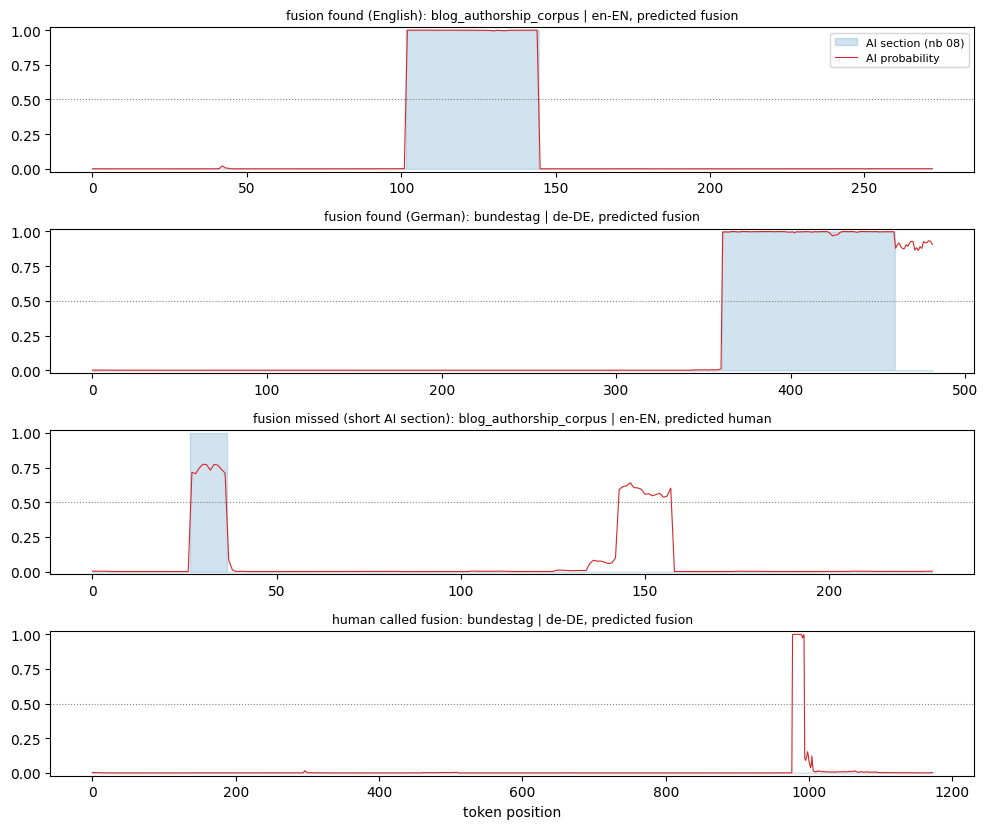

In [5]:
# AI probability along each example text (line) and the recovered AI section (blue band)
fig, axes = plt.subplots(len(EXAMPLES), 1, figsize=(10, 2.1 * len(EXAMPLES)), sharey=True)
for ax, (name, i) in zip(axes, EXAMPLES.items()):
    p, lab = PT[i], LAB[i]
    ax.fill_between(np.arange(len(p)), 0, lab, step="mid", color="tab:blue", alpha=0.2, label="AI section (nb 08)")
    ax.plot(p, color="tab:red", lw=0.8, label="AI probability")
    ax.axhline(0.5, color="grey", ls=":", lw=0.8)
    ax.set_title(f"{name}: {val['domain_lang'].iat[i]}, predicted {pred[i]}", fontsize=9)
    ax.set_ylim(-0.02, 1.02)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("token position")
plt.tight_layout()
plt.savefig(FIG / "xai_example_profiles.png", dpi=120)
plt.show()

In the two found texts the probability jumps from about 0 to 1 exactly where the AI section starts and falls back where it ends. In the German text the last sentence after the section also gets about 0.9 although it is labelled human: either the word diff of notebook 08 missed a rewritten sentence, or the tagger runs on past the end. In the missed text the tagger does see the short AI section (about 0.75), but also a second, false run of about 0.6 later; two medium-confident runs look like noise to the stacker. In the human text one short burst reaches 1.0.

In [6]:
# The example texts around their AI section: background = AI probability of the token, blue underline = AI section
def excerpt(i):
    p, s, lab, text = PT[i], ST[i], LAB[i], val["text"].iat[i]
    hot = np.flatnonzero(lab == 1) if lab.any() else np.flatnonzero(p > 0.5)
    hot = hot if len(hot) else np.array([int(np.argmax(p))])
    ctx = XC["context_tokens"]
    keep = list(range(max(hot[0] - ctx, 0), min(hot[-1] + 1 + ctx, len(p))))
    if len(keep) > 2 * ctx + 160:                                          # long AI section: show both of its ends
        keep = keep[:ctx + 80] + [None] + keep[-(ctx + 80):]
    ends = np.append(s[1:], len(text))
    parts = ["… "] if keep[0] > 0 else []
    for t in keep:
        if t is None:
            parts.append(" <b>[…]</b> ")
            continue
        style = f"background: rgba(220, 38, 38, {p[t]:.2f});"
        if lab[t] == 1:
            style += " border-bottom: 3px solid #2563eb;"
        parts.append(f'<span style="{style}">{html.escape(text[s[t]:ends[t]])}</span>')
    if keep[-1] < len(p) - 1:
        parts.append(" …")
    return "".join(parts)

display(HTML("".join(f"<p><b>{name}</b> ({val['domain_lang'].iat[i]}, {val['words'].iat[i]} words, true "
                     f"{val['label'].iat[i]}, predicted {pred[i]})</p>"
                     f"<p style='line-height: 1.7'>{excerpt(i)}</p>" for name, i in EXAMPLES.items())))

The English AI section starts with "Missing Part: (approximately 103 words)", a leftover of the generation prompt that the generator copied into its answer; the tagger is certain about it. The German section is a typical political appeal ("Das ist die reale Lebenssituation vieler deutscher Familien"). The missed AI section is a single short sentence ("It's always a thrill to hear"). The false alarm in the human Bundestag speech is an **English quotation** from the IPCC inside the German text: a switch of language looks like AI writing to the tagger.

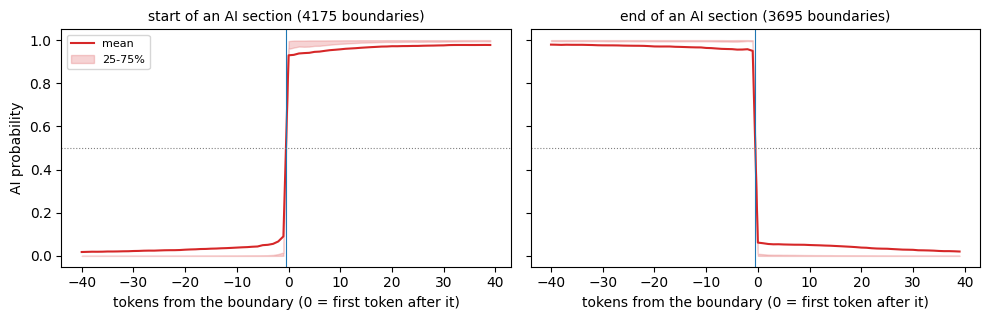

,-20,-10,-5,-2,-1,0,1,2,5,10,20
start of an AI section,0.029,0.039,0.050,0.067,0.091,0.929,0.931,0.938,0.945,0.957,0.971
end of an AI section,0.970,0.963,0.958,0.957,0.950,0.062,0.059,0.055,0.053,0.051,0.039


In [7]:
# Average AI probability around the start and the end of AI sections (boundaries with 40 clean tokens on each side)
b = XC["boundary_tokens"]
edges = {"start of an AI section": [], "end of an AI section": []}
for i in np.flatnonzero(val["spans"].notna()):
    lab, p = LAB[i], PT[i]
    d = np.diff(lab.astype(int))
    for key, step in (("start of an AI section", 1), ("end of an AI section", -1)):
        for t in np.flatnonzero(d == step) + 1:
            # clean boundaries only: b tokens of one kind before and b tokens of the other kind after
            if t - b >= 0 and t + b <= len(p) and len(set(lab[t - b:t])) == 1 and len(set(lab[t:t + b])) == 1:
                edges[key].append(p[t - b:t + b])
x = np.arange(-b, b)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for ax, (key, arr) in zip(axes, edges.items()):
    arr = np.array(arr)
    ax.plot(x, arr.mean(axis=0), color="tab:red", label="mean")
    ax.fill_between(x, *np.quantile(arr, [0.25, 0.75], axis=0), color="tab:red", alpha=0.2, label="25-75%")
    ax.axvline(-0.5, color="tab:blue", lw=0.8)
    ax.axhline(0.5, color="grey", ls=":", lw=0.8)
    ax.set_title(f"{key} ({len(arr)} boundaries)", fontsize=10)
    ax.set_xlabel("tokens from the boundary (0 = first token after it)")
axes[0].set_ylabel("AI probability")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "xai_boundaries.png", dpi=120)
plt.show()
pd.DataFrame({key: np.array(arr).mean(axis=0) for key, arr in edges.items()}, index=x).loc[
    [-20, -10, -5, -2, -1, 0, 1, 2, 5, 10, 20]].T.round(3)

Over about 4,000 clean boundaries the average probability changes from 0.09 to 0.93 between the last human token and the first AI token, and from 0.95 to 0.06 at the end of a section: the tagger locates boundaries to the token, not only to the sentence. Inside long sections it is surer (0.97) than near their edges.

In [8]:
# Words that the tagger marks as AI inside human texts (word = highest probability of its tokens), per language
WORD = re.compile(r"\w+")
rows = []
for i in np.flatnonzero(val["label"].eq("human")):
    text, p, s = val["text"].iat[i], PT[i], ST[i]
    found = [(m.start(), m.end(), m.group().lower()) for m in WORD.finditer(text)]
    if not found:
        continue
    ws, we = np.array([f[0] for f in found]), np.array([f[1] for f in found])
    word = np.searchsorted(ws, s, side="right") - 1                         # word of every token (or -1)
    inside = (word >= 0) & (s < we[np.maximum(word, 0)])
    wp = np.zeros(len(found))
    np.maximum.at(wp, word[inside], p[inside])
    rows.append(pd.DataFrame({"lang": val["lang"].iat[i], "word": [f[2] for f in found], "p": wp}))
words = pd.concat(rows, ignore_index=True)
words["flagged"] = words["p"] > 0.5
print(f"{len(words):,} words in {val['label'].eq('human').sum()} human texts; flagged as AI: "
      + ", ".join(f"{l} {g.mean():.2%}" for l, g in words.groupby("lang")["flagged"]))
stats = words.groupby(["lang", "word"]).agg(count=("p", "size"), flagged_share=("flagged", "mean"),
                                            mean_p=("p", "mean"))
stats = stats[stats["count"] >= XC["min_word_count"]]
stats.sort_values("flagged_share", ascending=False).groupby("lang").head(10).sort_index(
    level=0, sort_remaining=False).round(3)

3,853,040 words in 6674 human texts; flagged as AI: de-DE 0.94%, en-EN 0.70%


count  flagged_share  mean_p
lang  word                                           
de-DE herausforderungen    169          0.065   0.067
      entscheidungen       102          0.059   0.054
      bevölkerung          167          0.048   0.047
      schulen              130          0.046   0.039
      soziale              152          0.046   0.052
      sicherheit           407          0.042   0.044
      frieden              145          0.041   0.049
      verbessern           123          0.041   0.044
      stärken              198          0.040   0.037
      gemeinsamen          100          0.040   0.042
en-EN arxiv                100          0.120   0.080
      et                   155          0.090   0.092
      bias                 100          0.090   0.093
      phys                 158          0.089   0.067
      wave                 100          0.080   0.072
      demand               129          0.070   0.071
      analysis             177          0.068   0.075
      structure            128          0.062   0.075
      ultimately           100          0.060   0.073
      unique               134          0.060   0.066

False alarms are rare: under 1% of the words of human texts. No single word is a trigger: even the most often flagged words are flagged in at most 12% of their occurrences. In German they are abstract political nouns and verbs that AI rewrites of speeches use a lot (Herausforderungen, Entscheidungen, verbessern, stärken); in English partly reference fragments of arXiv papers ("arxiv", "et" al., "phys"), partly words often linked with LLM style ("ultimately", "unique").

## 2. Text level: which features decide? (SHAP values of the stacker)

SHAP values: (3004, 80, 3) (texts, features, classes); 0.3 min


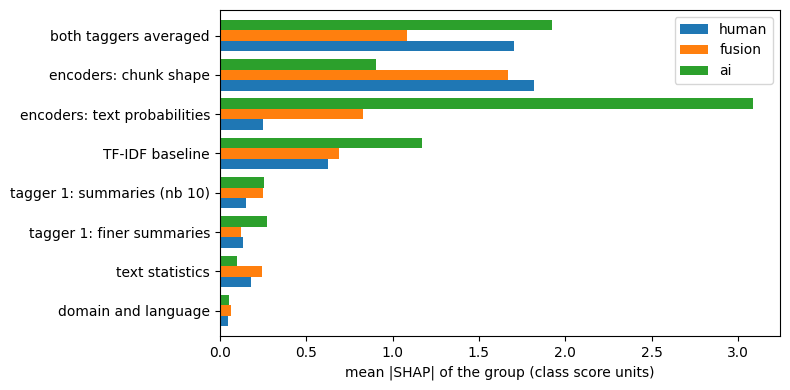

,human,fusion,ai,features,share of total
both taggers averaged,1.701,1.081,1.925,17,0.267
encoders: chunk shape,1.817,1.669,0.903,10,0.249
encoders: text probabilities,0.252,0.830,3.088,14,0.237
TF-IDF baseline,0.626,0.693,1.170,3,0.141
tagger 1: summaries (nb 10),0.152,0.249,0.256,8,0.037
tagger 1: finer summaries,0.133,0.123,0.272,9,0.030
text statistics,0.179,0.243,0.100,10,0.030
domain and language,0.047,0.064,0.051,9,0.009


In [9]:
# SHAP values (TreeSHAP) of a class-balanced validation sample plus the four examples, each by its own fold model
sample = val.groupby("label", group_keys=False).sample(n=XC["shap_texts"] // len(LABELS), random_state=42).index
rows_sv = np.union1d(sample.to_numpy(), list(EXAMPLES.values()))
t0 = time.time()
SV = np.zeros((len(rows_sv), Xv.shape[1], len(LABELS)))
for k, m in enumerate(models):
    sel = folds[rows_sv] == k
    SV[sel] = shap.TreeExplainer(m).shap_values(Xv[rows_sv[sel]])
print(f"SHAP values: {SV.shape} (texts, features, classes); {(time.time() - t0) / 60:.1f} min")

# a group's contribution is the sum of its features' SHAP values; its importance the mean absolute contribution
group_imp = pd.DataFrame({c: pd.DataFrame(SV[:, :, j], columns=NAMES).T.groupby(GROUP.values).sum().T.abs().mean()
                          for j, c in enumerate(LABELS)})
group_imp["features"] = GROUP.value_counts()
group_imp["share of total"] = group_imp[LABELS].sum(axis=1) / group_imp[LABELS].sum().sum()
group_imp = group_imp.sort_values("share of total", ascending=False)
ax = group_imp[LABELS][::-1].plot.barh(figsize=(8, 4), width=0.8)
ax.set_xlabel("mean |SHAP| of the group (class score units)")
plt.tight_layout()
plt.savefig(FIG / "xai_shap_groups.png", dpi=120)
plt.show()
group_imp.round(3)

Three groups carry three quarters of the decisions: the averaged taggers (27%), the chunk shape of the full-data encoder (25%) and its text-level probabilities (24%); the TF-IDF baseline still adds 14%. The classes use different evidence: **ai** is decided mainly by the encoders' text probabilities (a whole text in AI style), **human** and **fusion** by the chunk shape and the taggers (is there *any* AI part?). The first tagger's own summaries get little credit (7%) because the averaged taggers carry almost the same information, and SHAP splits credit between correlated features. The domain gets under 1% directly.

In [10]:
# The 15 most important single features: mean |SHAP| per class
feat_imp = pd.DataFrame(np.abs(SV).mean(axis=0), index=NAMES, columns=LABELS)
feat_imp.insert(0, "group", GROUP)
feat_imp["total"] = feat_imp[LABELS].sum(axis=1)
feat_imp.sort_values("total", ascending=False).head(15).round(3)

,group,human,fusion,ai,total
encoder_xlmr_full_min_human,encoders: chunk shape,1.523,0.052,0.260,1.835
encoder_xlmr_full_max_fusion,encoders: chunk shape,0.042,1.543,0.117,1.703
encoder_xlmr_full_first_ai,encoders: text probabilities,0.060,0.052,1.376,1.488
avg_tag_top10_mean,both taggers averaged,1.090,0.379,0.001,1.469
encoder_xlmr_full_mean_ai,encoders: text probabilities,0.022,0.037,1.347,1.407
tfidf_s_ai,TF-IDF baseline,0.111,0.289,0.945,1.345
avg_tag_std,both taggers averaged,0.085,0.596,0.103,0.785
tfidf_s_fusion,TF-IDF baseline,0.056,0.440,0.249,0.745
avg_tag_smooth16_min,both taggers averaged,0.029,0.018,0.686,0.733
tfidf_s_human,TF-IDF baseline,0.518,0.067,0.025,0.610


The single most important features match this: the lowest human probability over the chunks of a text (`min_human`: some chunk is not human) and the highest fusion probability over the chunks (`max_fusion`) decide human vs fusion; the first and mean chunk's AI probability decide ai; `avg_tag_top10_mean` (how sure the taggers are about their ten most AI-looking tokens) is the strongest tagger feature.

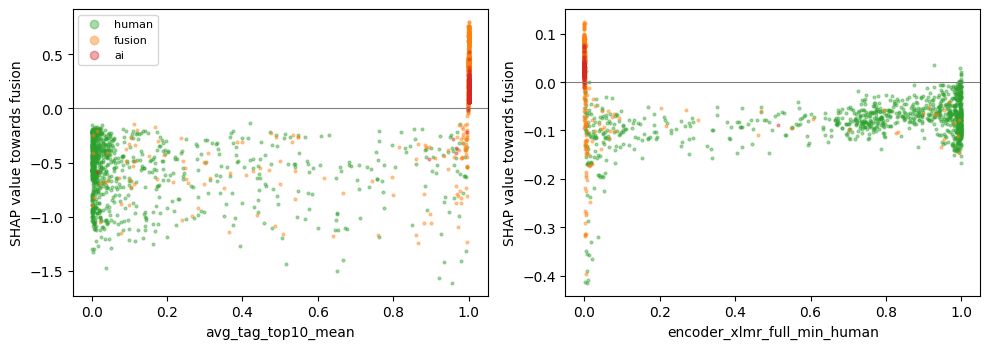

In [11]:
# SHAP value towards fusion against the feature value, for the top tagger feature and the top non-tagger feature
top = feat_imp.sort_values("total", ascending=False)
tagger_groups = ["tagger 1: summaries (nb 10)", "tagger 1: finer summaries", "both taggers averaged"]
pair = [top[top["group"].isin(tagger_groups)].index[0], top[~top["group"].isin(tagger_groups)].index[0]]
labels_sv = val["label"].to_numpy()[rows_sv]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, f in zip(axes, pair):
    j = NAMES.get_loc(f)
    for c, color in zip(LABELS, ["tab:green", "tab:orange", "tab:red"]):
        m = labels_sv == c
        ax.scatter(Xv[rows_sv[m], j], SV[m, j, LABELS.index("fusion")], s=4, alpha=0.4, color=color, label=c)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel(f)
    ax.set_ylabel("SHAP value towards fusion")
axes[0].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "xai_shap_dependence.png", dpi=120)
plt.show()

The stacker pushes towards fusion only when the taggers are nearly certain about some tokens (`avg_tag_top10_mean` close to 1); values of 0.5–0.95 push *away* from fusion, because in training such medium-confident runs were usually false alarms in human texts. This explains the missed example: its AI section got only about 0.75. A low `min_human` (some chunk clearly not human) pushes towards fusion and ai.

In [12]:
# Local explanations: the six features that pushed each example most towards its predicted class
at = {i: int(np.flatnonzero(rows_sv == i)[0]) for i in EXAMPLES.values()}
local = []
for name, i in EXAMPLES.items():
    jp, jt = LABELS.index(pred[i]), LABELS.index(val["label"].iat[i])
    sv = SV[at[i]]
    for f in np.argsort(-np.abs(sv[:, jp]))[:6]:
        local.append({"example": name, "feature": NAMES[f], "value": Xv[i, f],
                      "towards predicted": sv[f, jp], "towards true": sv[f, jt]})
pd.DataFrame(local).set_index(["example", "feature"]).round(3)

value  \
example                          feature                                 
fusion found (English)           encoder_xlmr_full_max_fusion    0.999   
                                 avg_tag_std                     0.364   
                                 tfidf_s_fusion                 -0.003   
                                 encoder_xlmr_full_mean_fusion  -0.001   
                                 mean_word_len                   4.788   
                                 tag_std                         0.364   
fusion found (German)            encoder_xlmr_full_max_fusion    1.000   
                                 avg_tag_std                     0.425   
                                 encoder_xlmr_full_mean_fusion  -0.000   
                                 tfidf_s_fusion                 -0.358   
                                 encoder_xlmr_full_first_fusion -0.000   
                                 avg_tag_top10_mean              1.000   
fusion missed (short AI section) encoder_xlmr_full_min_human     0.011   
                                 avg_tag_top10_mean              0.743   
                                 tfidf_s_human                  -1.014   
                                 encoder_xlmr_full_max_human     0.011   
                                 avg_tag_smooth8_max             0.751   
                                 avg_tag_sure_log                0.000   
human called fusion              encoder_xlmr_full_max_fusion    0.994   
                                 avg_tag_std                     0.119   
                                 encoder_xlmr_full_mean_fusion  -0.273   
                                 tag_std                         0.119   
                                 log_words                       6.579   
                                 avg_sent_max                    0.998   

                                                                 towards predicted  \
example                          feature                                             
fusion found (English)           encoder_xlmr_full_max_fusion                1.318   
                                 avg_tag_std                                 0.935   
                                 tfidf_s_fusion                              0.658   
                                 encoder_xlmr_full_mean_fusion               0.421   
                                 mean_word_len                              -0.376   
                                 tag_std                                     0.303   
fusion found (German)            encoder_xlmr_full_max_fusion                2.638   
                                 avg_tag_std                                 1.061   
                                 encoder_xlmr_full_mean_fusion               0.752   
                                 tfidf_s_fusion                              0.715   
                                 encoder_xlmr_full_first_fusion              0.423   
                                 avg_tag_top10_mean                          0.362   
fusion missed (short AI section) encoder_xlmr_full_min_human                 2.006   
                                 avg_tag_top10_mean                          1.225   
                                 tfidf_s_human                               0.685   
                                 encoder_xlmr_full_max_human                -0.643   
                                 avg_tag_smooth8_max                         0.528   
                                 avg_tag_sure_log                            0.481   
human called fusion              encoder_xlmr_full_max_fusion                1.046   
                                 avg_tag_std                                 0.542   
                                 encoder_xlmr_full_mean_fusion               0.507   
                                 tag_std                                     0.275   
                                 log_words                                  

In both found texts the largest push comes from the encoder's highest chunk-level fusion probability, then from the spread of the tagger probabilities (`avg_tag_std`: some tokens high, others low). The missed text was called human mainly because no chunk looks clearly non-human and the taggers' top tokens were not sure enough. The human Bundestag speech was called fusion for the same reasons as the real fusion texts: one chunk with the quotation looks like fusion to the encoder and the tagger.

In [13]:
# Distinct warnings logged in this session (should be empty), total time
print(f"total: {(time.time() - NOTEBOOK_START) / 60:.1f} min")
env.warnings_summary(P)

total: 4.7 min


[]